# Giới thiệu


Phân loại thể loại âm nhạc là một nhánh của lĩnh vực truy xuất thông tin âm nhạc (Music Information Retrieval – MIR). Một hệ thống gợi ý nhạc hiệu quả thường cần tổ chức và phân loại thể loại âm nhạc trước. Xử lý âm thanh cũng là một lĩnh vực nghiên cứu rộng, có những ứng dụng trong liệu pháp âm nhạc. Nhiều nền tảng như Spotify, Google Play và Apple Music cần xử lý dữ liệu nhạc ở quy mô lớn. Phân loại thể loại là một bài toán phức tạp, liên quan đến xử lý tín hiệu theo thời gian, chuỗi thời gian, ảnh phổ (spectrogram), hệ số phổ và trích xuất đặc trưng âm thanh để đưa vào mạng nơ-ron.


# Truy cập bộ dữ liệu


In [118]:
from pathlib import Path

GTZAN_ROOT = Path("/kaggle/input/datasets/andradaolteanu/gtzan-dataset-music-genre-classification")

# Hỗ trợ cả hai kiểu cấu trúc dữ liệu GTZAN trên Kaggle.
GTZAN_AUDIO = next((p for p in [
    GTZAN_ROOT / "Data" / "genres_original",
    GTZAN_ROOT / "genres_original",
] if p.is_dir()), None)

if GTZAN_AUDIO is None:
    raise FileNotFoundError(f"Không tìm thấy thư mục genres_original trong {GTZAN_ROOT}")

print("Thư mục âm thanh GTZAN:", GTZAN_AUDIO)


Thư mục âm thanh GTZAN: /kaggle/input/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/Data/genres_original


# Giới thiệu bộ dữ liệu


Bộ dữ liệu được sử dụng là **GTZAN**, một bộ dữ liệu rất phổ biến trong phân loại âm thanh, đôi khi được ví như “MNIST của âm thanh”.

GTZAN gồm **1.000 tệp âm thanh** thuộc **10 thể loại**, mỗi thể loại có 100 tệp:

1. Blues
2. Classical
3. Country
4. Disco
5. Hip-hop
6. Jazz
7. Metal
8. Pop
9. Reggae
10. Rock

**Thư mục `genres_original`**

> Chứa các tệp âm thanh gốc của 10 thể loại, mỗi thể loại có 100 bản ghi và mỗi bản ghi dài khoảng 30 giây.

**Thư mục `images_original`**

> Chứa các biểu diễn trực quan của âm thanh. Biểu diễn dạng hình ảnh cũng có thể được sử dụng làm đầu vào cho một số mô hình mạng nơ-ron.

**Các tệp CSV**

> Chứa những đặc trưng đã được trích xuất từ âm thanh. Một tệp tổng hợp giá trị trung bình và phương sai của các đặc trưng trên toàn bộ đoạn 30 giây. Tệp khác chia mỗi bản nhạc thành các đoạn 3 giây và lưu đặc trưng theo cấu trúc tương tự.


### Tìm hiểu và tự trích xuất đặc trưng âm thanh

Mặc dù bộ dữ liệu đã cung cấp sẵn một số đặc trưng, chúng ta sẽ tìm hiểu ý nghĩa và cách tính những đặc trưng đó. Từ dữ liệu âm thanh gốc, Notebook sẽ tự thực hiện bước trích xuất đặc trưng thay vì chỉ sử dụng kết quả có sẵn. Trên Kaggle, dữ liệu đầu vào được giữ nguyên vì thư mục `/kaggle/input` là thư mục chỉ đọc.


In [119]:
# Kaggle đã cung cấp dữ liệu trong /kaggle/input (chỉ đọc).
# Không cần tải/giải nén hoặc xóa các tệp dữ liệu có sẵn.


# Kiểm tra một tệp âm thanh mẫu


In [120]:
data_path = str(GTZAN_AUDIO / "blues" / "blues.00000.wav")


Tệp âm thanh có định dạng **`.wav`** (Waveform Audio File Format), được Microsoft và IBM phát triển. Đây thường là định dạng lưu âm thanh không nén, giữ chất lượng âm thanh tốt và được sử dụng rộng rãi trong thu âm, xử lý âm thanh. Đổi lại, dung lượng tệp thường lớn hơn các định dạng nén. WAV được tổ chức thành những khối dữ liệu (chunk) và tương thích với nhiều phần mềm âm thanh.

### Sử dụng thư viện `librosa`

Trong Python, thư viện **`librosa`** cung cấp các công cụ để đọc, phân tích và trích xuất đặc trưng âm thanh.


In [121]:
import librosa

# Load a .wav file using librosa
data, sr = librosa.load(data_path) # Sampling rate = 22050

Mặc định, `librosa.load()` đưa tín hiệu về **tần số lấy mẫu 22.050 Hz**. Chúng ta sẽ tìm hiểu ý nghĩa của tần số lấy mẫu ở phần tiếp theo. Trước hết, hãy nghe thử đoạn nhạc.


In [122]:
# Playing audio file
import IPython

IPython.display.Audio(data,rate=sr)

# Kiến thức cơ bản về xử lý tín hiệu


## Biểu đồ dạng sóng (Waveform)


##### **Có thể quan sát âm thanh vừa nghe không?** Có, bằng cách vẽ **Waveform**.


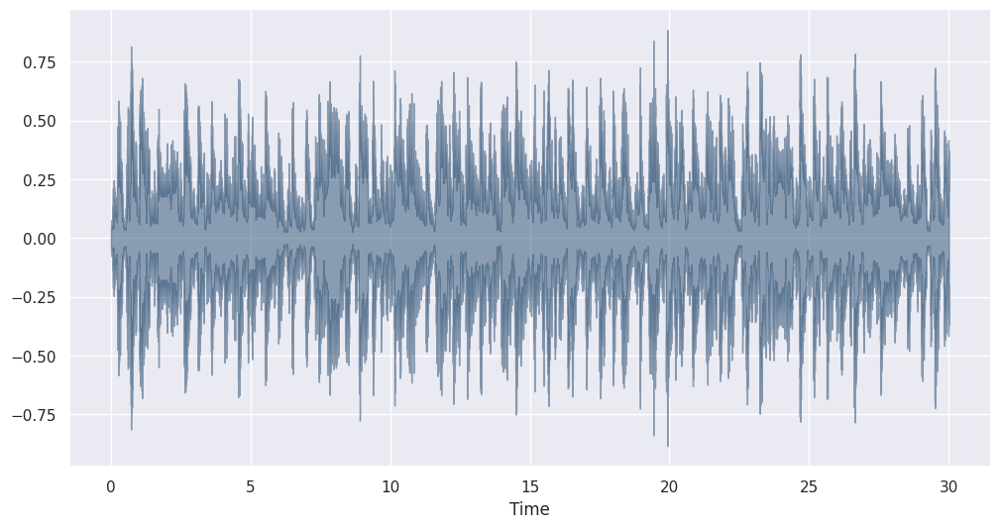

In [123]:
import matplotlib.pyplot as plt

# Wave form of the audio
plt.figure(figsize=(12,6))
librosa.display.waveshow(data, color="#2B4F72", alpha = 0.5)
plt.show()

- **Âm thanh** được tạo ra bởi sự dao động. Khi một vật dao động, nó làm các hạt không khí xung quanh chuyển động, truyền dao động thành sóng âm. Khi sóng âm đến tai, màng nhĩ dao động và não bộ cảm nhận thành âm thanh.

- **Waveform** thể hiện dạng của tín hiệu thông qua biên độ theo thời gian. Với tín hiệu âm thanh, nó cho thấy sự thay đổi giá trị biên độ (liên quan đến dao động áp suất âm) tại các thời điểm khác nhau.

- Trên **đồ thị Waveform**, trục ngang là thời gian, còn trục dọc là biên độ. Những đoạn có biên độ lớn biểu diễn dao động mạnh; những đoạn có biên độ nhỏ biểu diễn dao động yếu hơn.

- Tóm lại, Waveform giúp quan sát cấu trúc thời gian và sự thay đổi mức tín hiệu của một đoạn nhạc, nhưng chưa mô tả trực tiếp các thành phần tần số của nó.


## Tần số lấy mẫu (Sampling Rate)


> **Khi đọc tệp `.wav` bằng `librosa`, tần số lấy mẫu mặc định là 22.050 Hz. Con số này có ý nghĩa gì?**

> Âm thanh ngoài thực tế là **tín hiệu tương tự liên tục**. Để máy tính xử lý, tín hiệu cần được chuyển thành các mẫu rời rạc qua quá trình **lấy mẫu (sampling)**. **Sampling rate**, tính bằng Hertz (Hz), cho biết **số mẫu được lấy trong mỗi giây**.

> Tần số lấy mẫu có vai trò quan trọng trong việc biểu diễn tín hiệu tương tự bằng tín hiệu số. Theo **định lý lấy mẫu Nyquist–Shannon**, muốn tái tạo một tín hiệu giới hạn băng tần một cách chính xác, tần số lấy mẫu cần lớn hơn hai lần tần số cao nhất của tín hiệu.

> Việc lựa chọn tần số lấy mẫu còn liên quan đến tài nguyên tính toán. **Tần số lấy mẫu cao** tạo nhiều dữ liệu hơn, tốn dung lượng và thời gian xử lý; **tần số lấy mẫu thấp** có thể làm mất chi tiết, nhất là các thành phần tần số cao.

> Trong **Music Information Retrieval (MIR)**, sampling rate ảnh hưởng đến chất lượng trích xuất đặc trưng để nhận diện cao độ hoặc phân loại thể loại nhạc.

> Giá trị phù hợp tùy ứng dụng: CD thường sử dụng 44,1 kHz; các tác vụ âm thanh chuyên nghiệp có thể dùng 48 kHz, 96 kHz hoặc 192 kHz; các hệ thống xử lý giọng nói có thể dùng 8 kHz hoặc 16 kHz.

> Trong xử lý âm nhạc, 44,1 kHz được sử dụng phổ biến nhằm giữ phần lớn dải tần nghe được. Tuy vậy, tùy nhiệm vụ và năng lực tính toán, chúng ta có thể lựa chọn tốc độ lấy mẫu khác.

> **Tóm lại:** Sampling rate quyết định độ dày của các mẫu trong một giây và giới hạn dải tần có thể biểu diễn chính xác.


##### **Thử nghiệm với các tần số lấy mẫu khác nhau**


###### Sampling rate = 22050 Hz / Giá trị mặc định


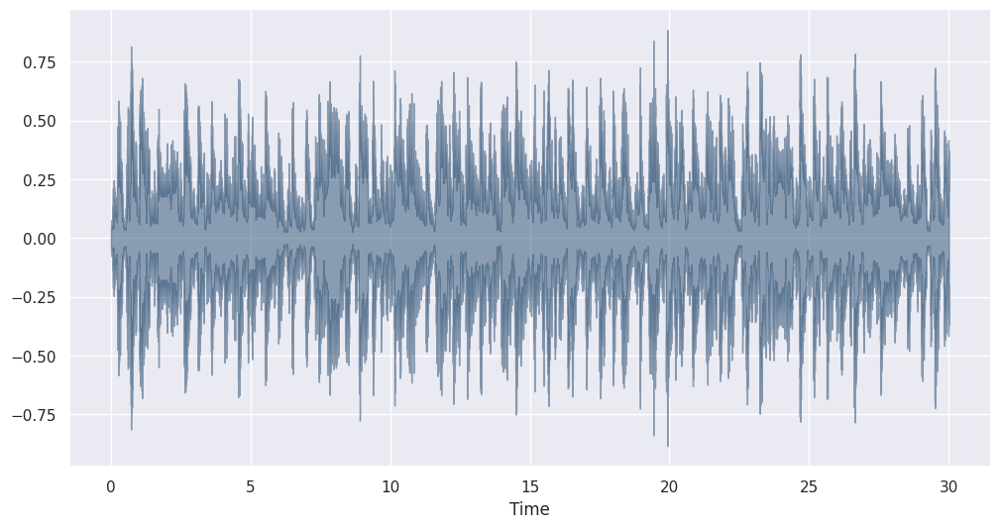

In [124]:
data, sr = librosa.load(data_path)

plt.figure(figsize=(12,6))
librosa.display.waveshow(data, color="#2B4F72", alpha = 0.5)
plt.show()

In [125]:
IPython.display.Audio(data,rate=sr)

###### Sampling rate = 44100 Hz / Giá trị phổ biến trong xử lý âm nhạc


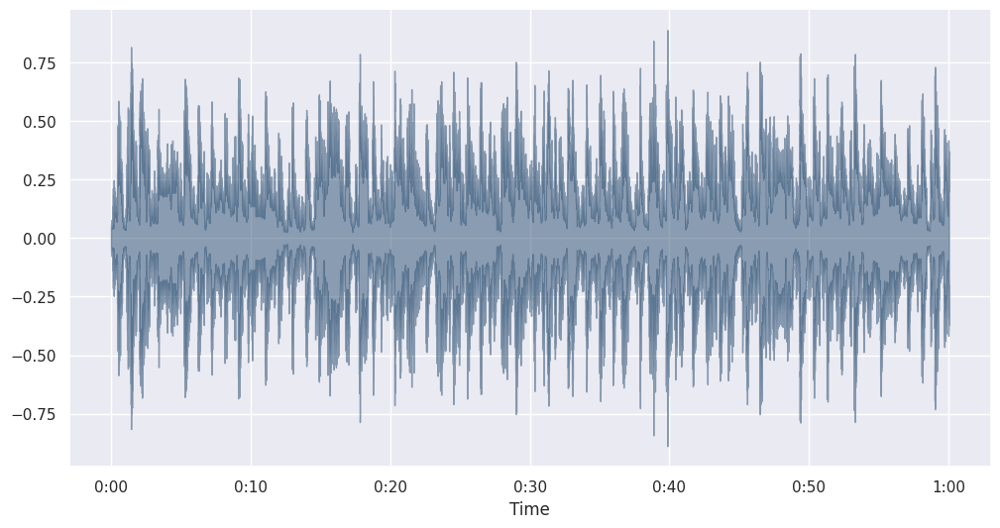

In [126]:
data, sr = librosa.load(data_path, sr=44100)

plt.figure(figsize=(12,6))
librosa.display.waveshow(data, color="#2B4F72", alpha = 0.5)
plt.show()

In [127]:
IPython.display.Audio(data,rate=sr)

> Chúng ta có thể nhận ra một chút khác biệt, nhưng không quá rõ. Tuy nhiên, số lượng mẫu trong mỗi giây đã **tăng gấp đôi**.


###### Sampling rate = 8000 Hz / Mức thường gặp trong một số ứng dụng giọng nói


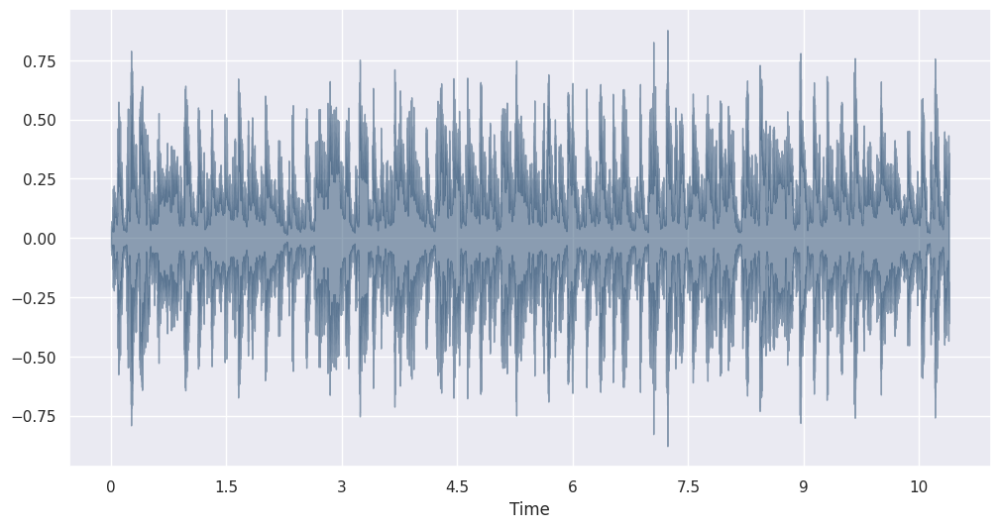

In [128]:
data, sr = librosa.load(data_path, sr=8000)

plt.figure(figsize=(12,6))
librosa.display.waveshow(data, color="#2B4F72", alpha = 0.5)
plt.show()

In [129]:
IPython.display.Audio(data,rate=sr)

> Khác biệt có thể không rõ khi nhìn Waveform nhưng dễ nhận ra hơn khi nghe. Nếu chú ý, bạn có thể thấy một số thành phần âm thanh tần số cao không còn được tái tạo rõ ràng.

###### **Thử các giá trị rất thấp**


###### Sampling rate = 1000 Hz


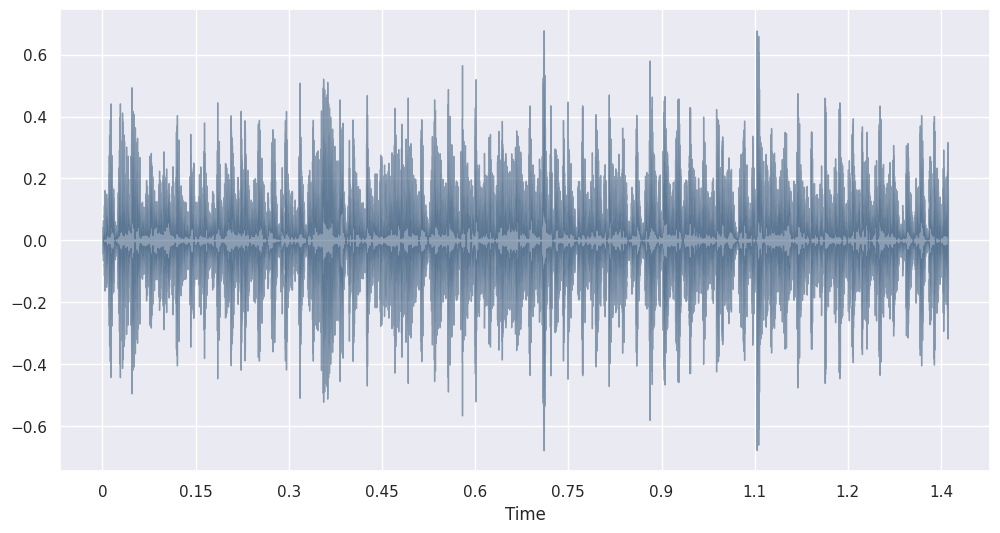

In [130]:
data, sr = librosa.load(data_path, sr=1000)

plt.figure(figsize=(12,6))
librosa.display.waveshow(data, color="#2B4F72", alpha = 0.5)
plt.show()

In [131]:
IPython.display.Audio(data,rate=sr)

###### Sampling rate = 10 Hz


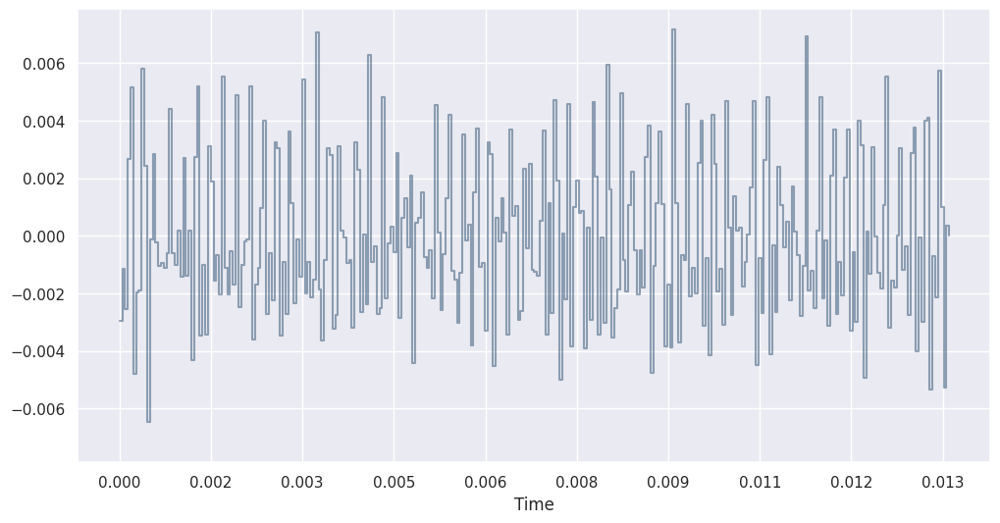

In [132]:
data, sr = librosa.load(data_path, sr=10)

plt.figure(figsize=(12,6))
librosa.display.waveshow(data, color="#2B4F72", alpha = 0.5)
plt.show()

In [133]:
IPython.display.Audio(data,rate=sr)

### Âm thanh đã biến đi đâu?

Khi giảm tần số lấy mẫu xuống mức cực thấp, hầu hết các thành phần âm thanh có tần số cao sẽ không còn được giữ lại trong quá trình lấy mẫu lại đúng cách. Ví dụ, với sampling rate 10 Hz, giới hạn Nyquist chỉ là 5 Hz, thấp hơn ngưỡng nghe thông thường của con người (khoảng 20 Hz). Vì vậy, tín hiệu sau khi xử lý có thể gần như không còn nghe được.


> **Waveform là cách biểu diễn tín hiệu âm thanh trong một chiều theo thời gian**, cho biết sự biến thiên biên độ và thời lượng tín hiệu. Tuy nhiên, chỉ quan sát Waveform sẽ khó biết các thành phần tần số nào đang tồn tại. Để phân tích tần số, chúng ta sử dụng các biểu diễn phổ như Spectrogram.


## Biểu đồ phổ (Spectrogram)


> Khác với Waveform, **Spectrogram** phân tích tín hiệu âm thanh thành những thành phần tần số và biểu diễn độ mạnh của các thành phần ấy theo thời gian. Vì vậy, Spectrogram phù hợp để quan sát đặc trưng liên quan đến tần số, cao độ và âm sắc của âm nhạc. Nó rất hữu ích trong nhận dạng giọng nói, phân tích âm nhạc và nghiên cứu âm thanh phức tạp. Tuy nhiên, để đánh giá đầy đủ nhịp điệu và cấu trúc âm nhạc, chúng ta có thể cần thêm những đặc trưng khác.

> **Hiểu đơn giản:** Spectrogram cho biết ở từng thời điểm của đoạn âm thanh, những tần số nào xuất hiện và mạnh hay yếu.


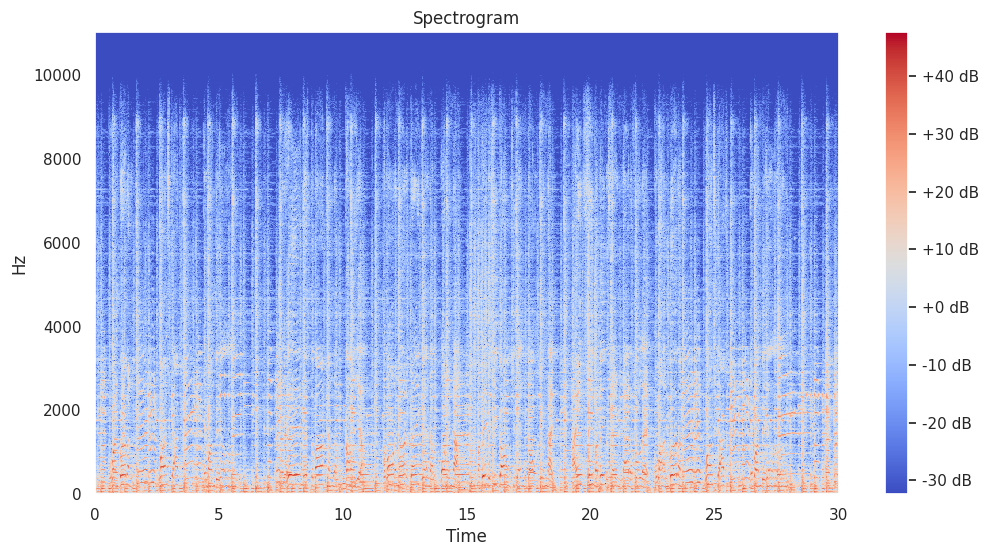

In [134]:
# Let load .wav file with default sampling rate of 22,050Hz
data, sr = librosa.load(data_path)

# Spectrogram of the audio
stft=librosa.stft(data)
stft_db=librosa.amplitude_to_db(abs(stft))
plt.figure(figsize=(12,6))
librosa.display.specshow(stft_db,sr=sr,x_axis='time',y_axis='hz')
plt.title('Spectrogram')
plt.colorbar(format='%+2.0f dB')

Bây giờ hãy quan sát Spectrogram khi đọc tệp `.wav` với tần số lấy mẫu **8.000 Hz**.


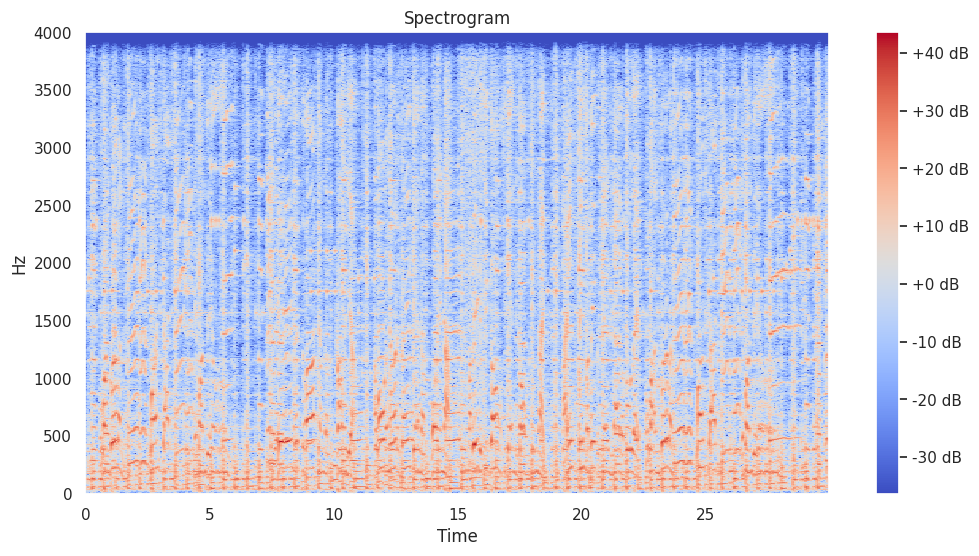

In [135]:
# Let load .wav file with default sampling rate of 22,050Hz
data, sr = librosa.load(data_path, sr=8000)

# Spectrogram of the audio
stft=librosa.stft(data)
stft_db=librosa.amplitude_to_db(abs(stft))
plt.figure(figsize=(12,6))
librosa.display.specshow(stft_db,sr=sr,x_axis='time',y_axis='hz')
plt.title('Spectrogram')
plt.colorbar(format='%+2.0f dB')

> **Hãy nhớ lại lúc chúng ta nghe thấy các thành phần âm thanh tần số cao bị suy giảm khi hạ sampling rate.**

> Waveform thể hiện biên độ theo thời gian nên khó cho thấy trực tiếp những thành phần tần số nào đã mất. Ngược lại, Spectrogram biểu diễn sự phân bố phổ theo thời gian, giúp quan sát rõ hơn những khác biệt ấy.

> Với sampling rate **8.000 Hz**, tần số Nyquist chỉ còn **4.000 Hz**. Vì thế, Spectrogram một phía chỉ hiển thị dải từ 0 đến 4.000 Hz, thay vì đến khoảng 11.025 Hz như khi lấy mẫu ở 22.050 Hz. Những thành phần tần số cao hơn cần được lọc bỏ trước khi giảm mẫu để tránh chồng phổ (aliasing).

> Tóm lại, Waveform cho cái nhìn tổng quan về dao động biên độ, còn Spectrogram giúp phân tích sâu hơn về thành phần tần số, đặc biệt hữu ích khi nghiên cứu âm thanh có cấu trúc phức tạp.


## Phổ Mel (Mel-Spectrogram)


> Spectrogram cung cấp thông tin chi tiết về phổ theo thời gian, nhưng cách chia đều tần số trên trục tuyến tính không hoàn toàn giống cách tai người cảm nhận cao độ. Con người thường phân biệt sự thay đổi ở vùng tần số thấp tốt hơn so với vùng tần số rất cao.

> **Mel-Spectrogram** sử dụng **thang Mel**, một thang đo được thiết kế để gần với cảm nhận cao độ của con người. Vì vậy, biểu diễn này thường được dùng trong nhận dạng tiếng nói và phân tích âm nhạc.

> Mel-Spectrogram cũng biểu diễn phổ công suất của các khung tín hiệu ngắn, nhưng các thành phần phổ được nhóm theo những bộ lọc đặt trên thang Mel. Cách biểu diễn này dành độ phân giải tương đối nhiều hơn cho dải tần thấp và ít hơn cho dải tần cao.

> Về mặt ứng dụng, Mel-Spectrogram giúp làm nổi bật những đặc điểm phổ có ý nghĩa với hệ thính giác, phục vụ phân tích giọng nói, nhạc cụ và các bài toán nhận dạng âm thanh.

**Các bước tạo Mel-Spectrogram:**

1. Tính phổ của tín hiệu theo từng khung thời gian.
2. Chiếu phổ lên các **bộ lọc Mel** (thường là các bộ lọc tam giác có chồng lấn).
3. Có thể lấy log năng lượng phổ Mel để thu được **Log-Mel Spectrogram**.

> **Tóm lại:** Spectrogram và Mel-Spectrogram đều mô tả thành phần tần số theo thời gian; điểm khác biệt là Mel-Spectrogram dùng cách chia dải tần gần hơn với đặc điểm cảm nhận âm thanh của con người.


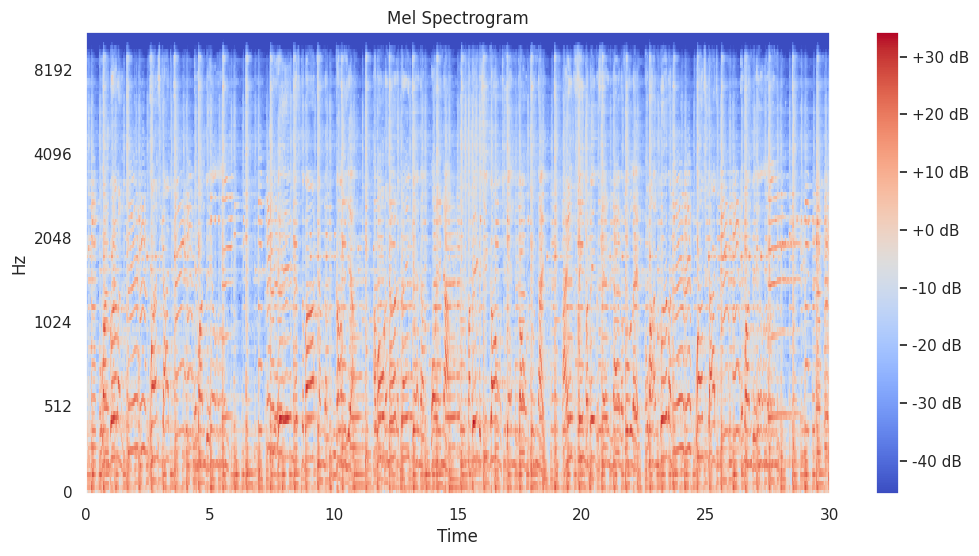

In [136]:
# Let load .wav file with default sampling rate of 22,050Hz
data, sr = librosa.load(data_path)

# Creating log mel spectrogram
plt.figure(figsize=(12, 6))
spectrogram = librosa.feature.melspectrogram(y=data, sr=sr, n_mels=128, fmax=sr//2)
spectrogram = librosa.power_to_db(spectrogram)
librosa.display.specshow(spectrogram, y_axis='mel', fmax=sr//2, x_axis='time');
plt.title('Mel Spectrogram')
plt.colorbar(format='%+2.0f dB')

# Năng lượng hiệu dụng RMS (Root Mean Square Energy)


> Trong xử lý tín hiệu âm thanh, **RMS** thường dùng để đo mức biên độ hiệu dụng của tín hiệu trong một khung thời gian.

**Cách tính RMS:**

- **Bình phương (Square):** Bình phương từng mẫu để giá trị âm và dương không triệt tiêu nhau khi cộng.
- **Lấy trung bình (Mean):** Tính trung bình các giá trị bình phương để biểu diễn mức năng lượng trung bình theo khung.
- **Lấy căn (Root):** Lấy căn bậc hai để đưa kết quả về cùng đơn vị với biên độ ban đầu.

**Ứng dụng trong âm thanh:**

- RMS phản ánh mức tín hiệu tổng thể và nhấn mạnh những mẫu có biên độ lớn.
- Ví dụ, một đoạn âm thanh có nhiều khoảng lặng nhưng xen kẽ vài đỉnh biên độ lớn vẫn có thể có RMS đáng kể.

**Vì sao RMS quan trọng?**

RMS thường có liên hệ với cảm nhận âm lượng, dù không đồng nhất với độ lớn âm thanh mà người nghe cảm nhận. Nó được dùng trong chuẩn hóa âm thanh, phân tích mức tín hiệu và các thuật toán nén dải động.


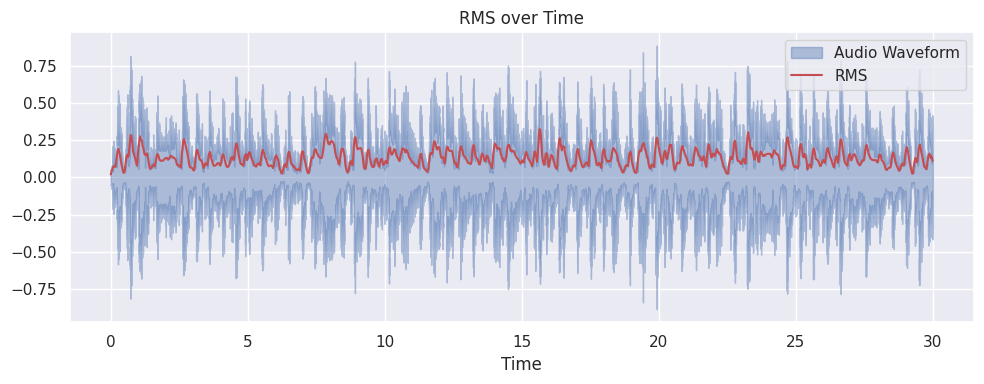

In [137]:
# Let load .wav file with default sampling rate of 22,050Hz
data, sr = librosa.load(data_path)

# Compute RMS
rms = librosa.feature.rms(y=data)

# Plot RMS
plt.figure(figsize=(10, 4))
librosa.display.waveshow(data, sr=sr, alpha=0.4, label='Audio Waveform')
plt.plot(librosa.times_like(rms[0], sr=sr), rms[0], color='r', label='RMS')
plt.legend(loc='upper right')
plt.title('RMS over Time')
plt.tight_layout()
plt.show()

## Tỷ lệ đổi dấu (Zero-Crossing Rate – ZCR)


> **Zero-Crossing Rate (ZCR)** là đặc trưng thể hiện mức độ thường xuyên tín hiệu đổi dấu, chẳng hạn chuyển từ giá trị dương sang âm hoặc ngược lại.

**ZCR cho biết điều gì?**

- **Thành phần tần số:** ZCR cao thường đi kèm với tín hiệu dao động nhanh; ZCR thấp thường thấy ở những tín hiệu dao động chậm hơn. Tuy nhiên, ZCR không trực tiếp xác định tần số của tín hiệu phức hợp.
- **Phát hiện nhiễu:** Một số loại nhiễu tần số cao có thể làm ZCR tăng.
- **Phân tích giọng nói:** Những đoạn âm hữu thanh (như nguyên âm) thường có ZCR thấp hơn các đoạn vô thanh (như âm /s/ hoặc /f/).

Đặc trưng này được sử dụng trong nhận dạng giọng nói và truy xuất thông tin âm nhạc. Những âm thanh có tính bộ gõ mạnh, thường gặp trong một số đoạn nhạc rock hoặc metal, có thể xuất hiện ZCR cao.


ZRC = 131


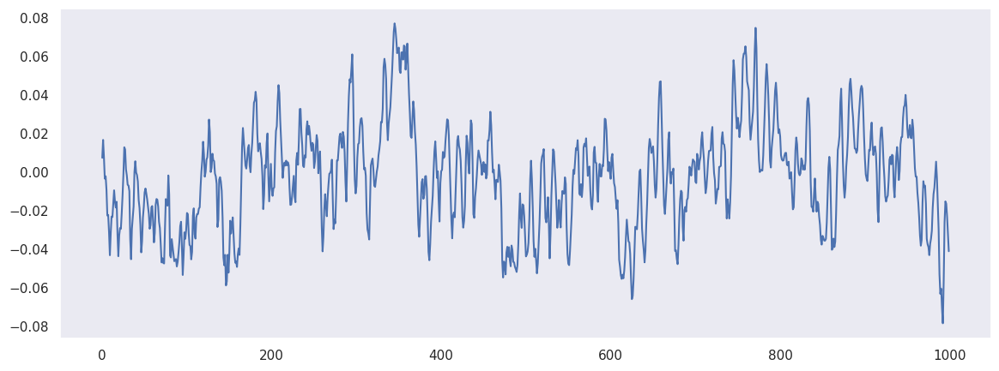

In [138]:
## Example of ZCR

# Let load .wav file with default sampling rate of 22,050Hz
data, sr = librosa.load(data_path)

# Calculate ZRC of the first 1000 data point of our song
n0 = 0
n1 = 1000
plt.figure(figsize=(14, 5))
plt.plot(data[n0:n1])
plt.grid()

zero_crossings = librosa.zero_crossings(data[n0:n1], pad=False)
print(f'ZRC = {sum(zero_crossings)}')

## Tần số roll-off của phổ (Spectral Rolloff)


> **Spectral Rolloff** là đại lượng mô tả hình dạng phổ tín hiệu. Đây là ngưỡng tần số mà phía dưới nó chứa một tỷ lệ nhất định của tổng năng lượng hoặc độ lớn phổ, tùy quy ước tính toán.

> Spectral Rolloff thường được xác định bằng một tỷ lệ khoảng **85%–95%**. Chẳng hạn, với ngưỡng 85%, ta tìm tần số mà tổng độ lớn phổ tích lũy từ thấp đến đó đạt 85% tổng độ lớn phổ.

**Ý nghĩa của Spectral Rolloff:**

- **Hình dạng phổ:** Rolloff thấp thường cho thấy phổ tập trung nhiều ở vùng tần số thấp; rolloff cao cho thấy phân bố phổ kéo dài hơn về phía tần số cao.
- **Thành phần họa âm:** Giá trị rolloff có thể phản ánh sự hiện diện của các họa âm cao hoặc nhiễu cao tần.
- **Phân biệt âm thanh:** Có thể hỗ trợ phân biệt âm thanh giàu họa âm với những âm thanh có nhiều thành phần nhiễu hoặc âm bồi cao.

**Ứng dụng:**

- **Truy xuất thông tin âm nhạc:** Nhận diện nhạc cụ hoặc phân loại thể loại.
- **Xử lý tiếng nói:** Mô tả các âm vị hoặc đặc điểm giọng nói.
- **Phân tích nhiễu:** Xác định sự hiện diện của thành phần nhiễu tần số cao.

> **Tóm lại:** Spectral Rolloff tóm tắt phân bố phổ bằng một ngưỡng tần số và cung cấp thông tin bổ sung về âm sắc của tín hiệu.


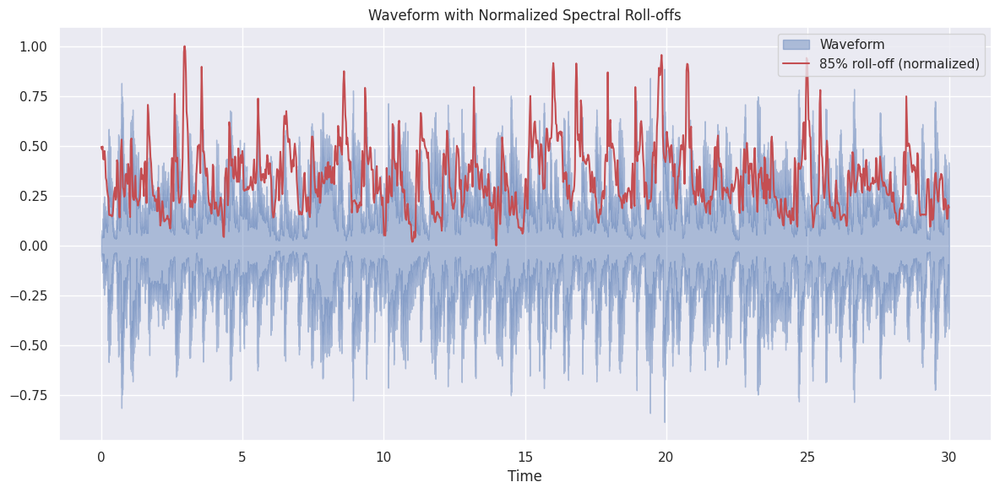

In [139]:
import sklearn.preprocessing

# Function to normalize an array
def normalize(x, axis=0):
    return sklearn.preprocessing.minmax_scale(x, axis=axis)

# Load the audio file with default sampling rate of 22,050Hz
data, sr = librosa.load(data_path)

# Compute and norm the spectral roll-off
rolloff_85 = librosa.feature.spectral_rolloff(y=data, sr=sr, roll_percent=0.85)[0]
rolloff_85_norm = normalize(rolloff_85)

# Plot the waveform and normalized spectral roll-offs
plt.figure(figsize=(12, 6))
librosa.display.waveshow(data, sr=sr, alpha=0.4, label='Waveform')
times = librosa.times_like(rolloff_85)
plt.plot(times, rolloff_85_norm, color='r', label='85% roll-off (normalized)')

plt.title('Waveform with Normalized Spectral Roll-offs')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## Trọng tâm phổ (Spectral Centroid)


> **Spectral Centroid** là đặc trưng mô tả trọng tâm của phổ âm thanh theo tần số. Chúng ta có thể hình dung nó như **điểm cân bằng** của phổ, trong đó mỗi tần số được gán trọng số theo độ lớn thành phần phổ.

**Hiểu theo trực giác:**

Tưởng tượng một chiếc bập bênh: điểm cân bằng phụ thuộc vào trọng lượng phân bố ở hai bên. Tương tự, Spectral Centroid cho biết phổ tín hiệu tập trung nhiều ở vùng tần số thấp hay cao. Nếu các thành phần tần số thấp chiếm ưu thế, centroid thường thấp và âm thanh có thể được cảm nhận là trầm hơn. Nếu thành phần tần số cao mạnh, centroid thường lớn hơn và âm thanh có thể sáng hoặc sắc hơn.

**Ứng dụng:**

- **Phân tích âm sắc:** Hỗ trợ mô tả cảm giác sáng/tối của âm thanh.
- **Truy xuất thông tin âm nhạc:** Hỗ trợ phân biệt nhạc cụ, thể loại hoặc đặc điểm biểu cảm.
- **Xử lý tiếng nói:** Hỗ trợ phân tích các âm vị.
- **Thiết kế âm thanh:** Có thể dùng khi điều chỉnh đặc tính phổ của âm thanh tổng hợp.

> Tuy nhiên, Spectral Centroid chỉ là một giá trị, không thể mô tả toàn bộ âm sắc. Do đó, nó thường được kết hợp với những đặc trưng phổ khác.

> **Tóm lại:** Spectral Centroid lượng hóa vị trí trọng tâm của phổ và góp phần mô tả độ sáng của âm thanh.


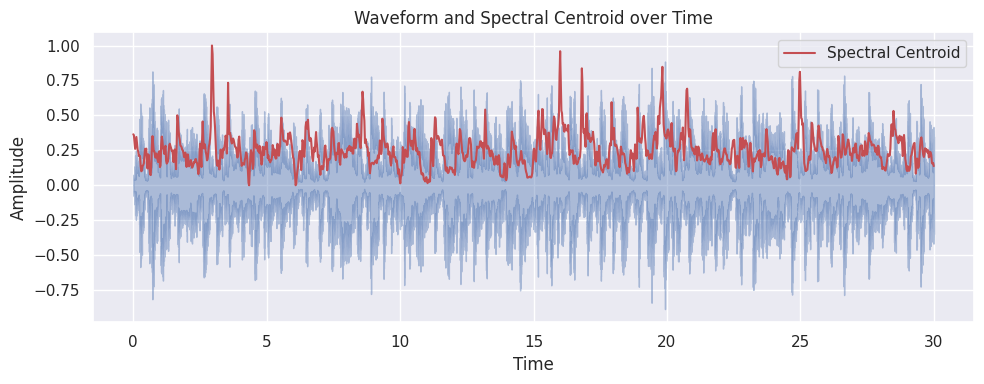

In [140]:
# Let load .wav file with default sampling rate of 22,050Hz
data, sr = librosa.load(data_path)

# Compute the spectral centroid
spectral_centroids = librosa.feature.spectral_centroid(y=data, sr=sr)

# Normalize function
def normalize(x, axis=0):
    return sklearn.preprocessing.minmax_scale(x, axis=axis)

# Plotting
plt.figure(figsize=(10, 4))
librosa.display.waveshow(data, sr=sr, alpha=0.4)
frames = range(len(spectral_centroids[0]))
t = librosa.frames_to_time(frames)
plt.plot(t, normalize(spectral_centroids[0]), color='r', label='Spectral Centroid')

# Set labels and title
plt.title('Waveform and Spectral Centroid over Time')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## Độ rộng phổ (Spectral Bandwidth)


> **Spectral Bandwidth** mô tả độ phân tán của các thành phần tần số trong tín hiệu. Nói đơn giản, nó cho biết phổ trải rộng hay tập trung quanh trọng tâm phổ.

- **Bandwidth hẹp:** Phần lớn độ lớn phổ tập trung trong một vùng tần số nhỏ. Ví dụ, một sóng sin thuần có phổ rất hẹp vì chỉ gồm một tần số chính.
- **Bandwidth rộng:** Thành phần phổ phân bố trên dải tần rộng hơn. Ví dụ, nhiễu trắng có phổ trải rộng ở nhiều tần số.

Spectral Bandwidth thường được tính dựa trên **Spectral Centroid**: centroid xác định trọng tâm, còn bandwidth đo mức độ phân tán xung quanh trọng tâm đó.

**Ứng dụng trong xử lý âm thanh:**

- **Phân tích âm nhạc:** Hỗ trợ phân biệt những đoạn âm có tính cao độ rõ với các đoạn giàu nhiễu.
- **Xử lý tiếng nói:** Mô tả một số đặc điểm âm vị.
- **Phân loại âm thanh:** So sánh các âm dựa trên độ trải rộng của phổ.

> **Tóm lại:** Spectral Bandwidth cho biết độ phân tán tần số của tín hiệu, bổ sung thông tin cho các đặc trưng phổ khác.


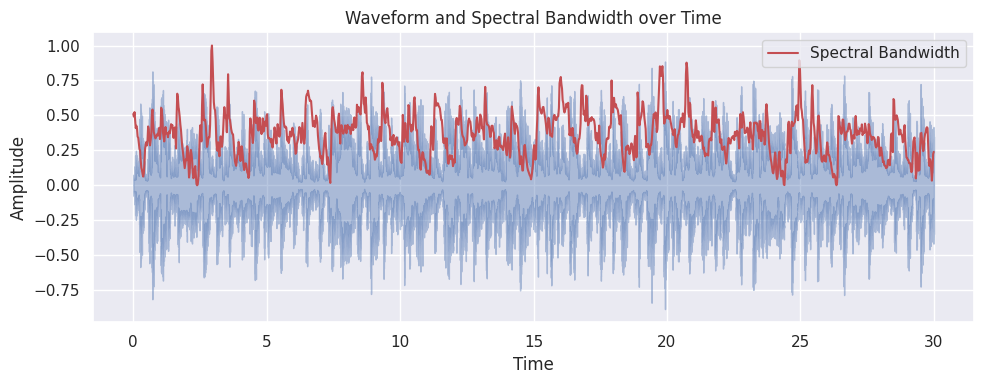

In [141]:
# Let load .wav file with default sampling rate of 22,050Hz
data, sr = librosa.load(data_path)

# Compute the spectral bandwidth
spectral_bandwidth = librosa.feature.spectral_bandwidth(y=data, sr=sr)

# Plotting
plt.figure(figsize=(10, 4))
librosa.display.waveshow(data, sr=sr, alpha=0.4)
frames = range(len(spectral_bandwidth[0]))
t = librosa.frames_to_time(frames)
plt.plot(t, normalize(spectral_bandwidth[0]), color='r', label='Spectral Bandwidth')

# Set labels and title
plt.title('Waveform and Spectral Bandwidth over Time')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## Đặc trưng Chroma


> **Chroma** là đặc trưng phổ biến trong xử lý âm nhạc, mô tả năng lượng theo **12 lớp cao độ** (pitch class), hỗ trợ biểu diễn hòa âm và hợp âm.

**Nguyên lý:**

Trong âm nhạc phương Tây có 12 lớp cao độ, tương ứng với các nốt C, C#, D, D#, ..., B. Chroma tổng hợp năng lượng của cùng một tên nốt ở nhiều quãng tám, nhờ đó biểu diễn có xu hướng ít phụ thuộc hơn vào quãng tám cụ thể và tập trung vào cấu trúc hòa âm.

**Ứng dụng:**

- **Nhận dạng hợp âm:** Phân tích sự phân bố năng lượng theo lớp cao độ.
- **Tìm kiếm và so sánh âm nhạc:** Phát hiện các đoạn có tiến trình hòa âm gần giống nhau; hỗ trợ tìm những bản cover.
- **Chép nhạc:** Hỗ trợ suy ra cấu trúc cao độ và hòa âm.
- **Xác định giọng (key):** Hỗ trợ xác định tông của bản nhạc.

Chroma thường được tính từ **STFT**. Độ lớn phổ được ánh xạ vào 12 nhóm cao độ; các thành phần cùng tên nốt ở nhiều quãng tám được cộng hoặc tổng hợp vào một nhóm Chroma.

Ví dụ, các nốt **C1, C2, C3...** đều đóng góp vào nhóm Chroma của nốt **C**.

> **Tóm lại:** Chroma cung cấp biểu diễn ngắn gọn của nội dung cao độ và hòa âm, hữu ích trong nhiều bài toán truy xuất thông tin âm nhạc.


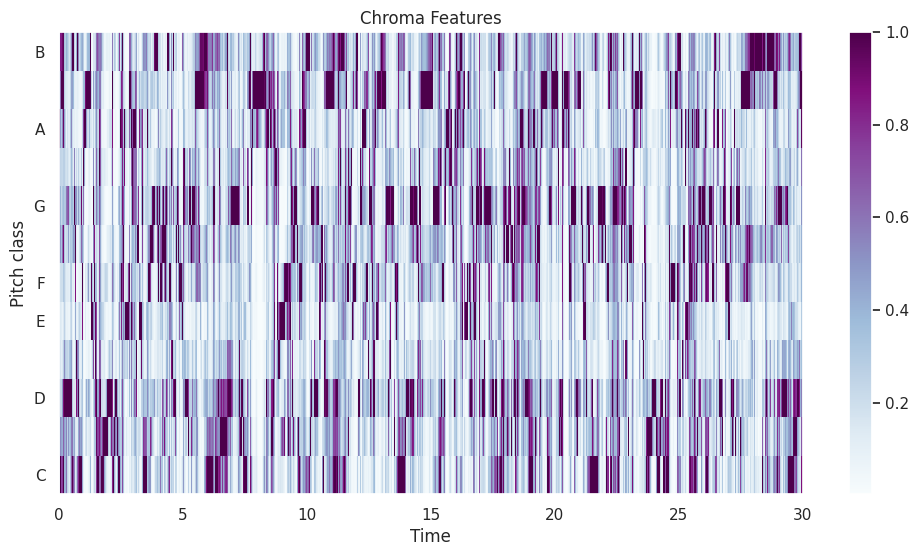

In [142]:
# Let load .wav file with default sampling rate of 22,050Hz
data, sr = librosa.load(data_path)

chroma = librosa.feature.chroma_stft(y=data,sr=sr)
plt.figure(figsize=(12,6))
librosa.display.specshow(chroma,sr=sr,x_axis="time",y_axis="chroma",cmap="BuPu")
plt.colorbar()
plt.title("Chroma Features")
plt.show()

## Thành phần hòa âm và bộ gõ (Harmonic and Percussive)


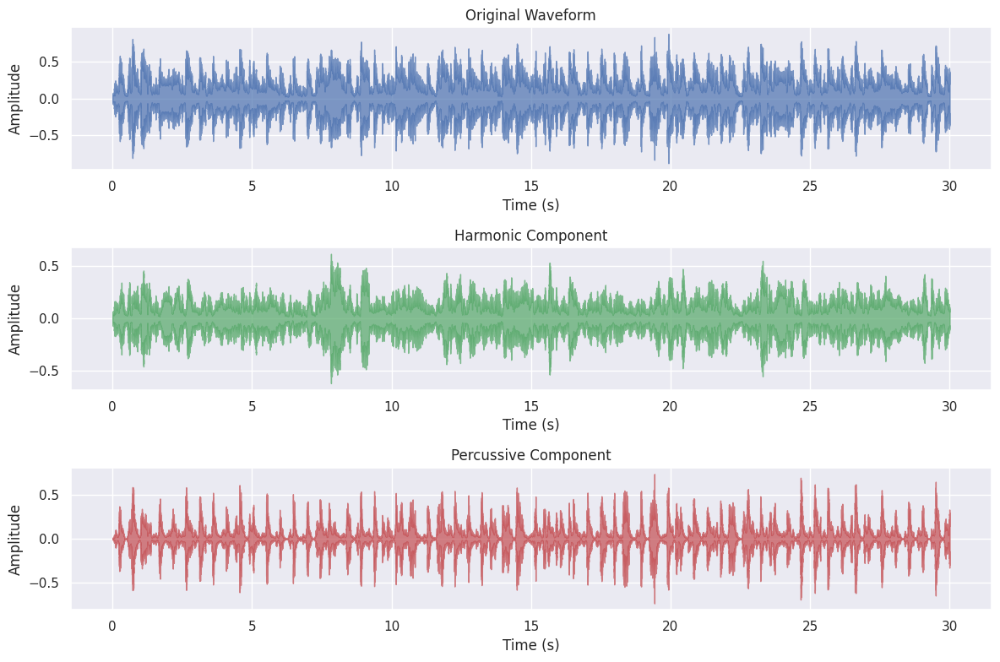

In [143]:
# Let load .wav file with default sampling rate of 22,050Hz
data, sr = librosa.load(data_path)

# Separate the harmonic and percussive components
data_harmonic, data_percussive = librosa.effects.hpss(data)

# Plot the original, harmonic, and percussive waveforms
plt.figure(figsize=(12, 8))

# Original waveform
plt.subplot(3, 1, 1)
librosa.display.waveshow(data, sr=sr, alpha=0.7)
plt.title('Original Waveform')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')

# Harmonic component
plt.subplot(3, 1, 2)
librosa.display.waveshow(data_harmonic, sr=sr, alpha=0.7, color='g')
plt.title('Harmonic Component')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')

# Percussive component
plt.subplot(3, 1, 3)
librosa.display.waveshow(data_percussive, sr=sr, alpha=0.7, color='r')
plt.title('Percussive Component')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')

plt.tight_layout()
plt.show()

## Hệ số cepstral trên thang Mel (MFCC)


> **Mel-Frequency Cepstral Coefficients (MFCC)** là tập các đặc trưng thường dùng trong xử lý âm thanh, đặc biệt là nhận dạng tiếng nói. MFCC cung cấp biểu diễn gọn về hình dạng phổ trong những khoảng thời gian ngắn và dựa trên các đặc điểm cảm nhận âm thanh của con người.

**Nguyên lý:**

- **Thang Mel:** Biểu diễn cao độ dựa trên cảm nhận của người nghe. Tai người phân biệt sự thay đổi ở vùng tần số thấp và cao không theo cùng một tỷ lệ, nên thang Mel có dạng phi tuyến.
- **Phân tích cepstrum:** Biến đổi thông tin phổ qua phép lấy log và phép biến đổi tiếp theo, tạo ra các hệ số mô tả đường bao phổ tương đối gọn.

**Các bước tính MFCC:**

1. **Chia khung tín hiệu:** Chia âm thanh thành các khung ngắn, thường cỡ 20–40 ms.
2. **Tính phổ công suất:** Ước lượng thành phần tần số trong từng khung.
3. **Áp dụng bộ lọc Mel:** Đưa phổ qua tập các bộ lọc bố trí theo thang Mel.
4. **Lấy log năng lượng:** Tính log của năng lượng thu được từ từng bộ lọc.
5. **Biến đổi Cosine rời rạc (DCT):** Chuyển log năng lượng Mel thành các hệ số cepstral. Tùy ứng dụng, ta có thể giữ một số hệ số đầu thay vì dùng toàn bộ.

**Ứng dụng:**

- **Nhận dạng tiếng nói:** Mô tả đặc trưng phổ ngắn hạn phục vụ phân loại âm thanh lời nói.
- **Truy xuất thông tin âm nhạc:** Hỗ trợ phân loại thể loại hoặc nhận diện nhạc cụ.
- **Xác thực giọng nói:** Có thể dùng trong các hệ thống sinh trắc học giọng nói.

> **Tóm lại:** MFCC là biểu diễn cô đọng của hình dạng phổ âm thanh, hữu ích cho những bài toán phân tích tiếng nói và âm nhạc.


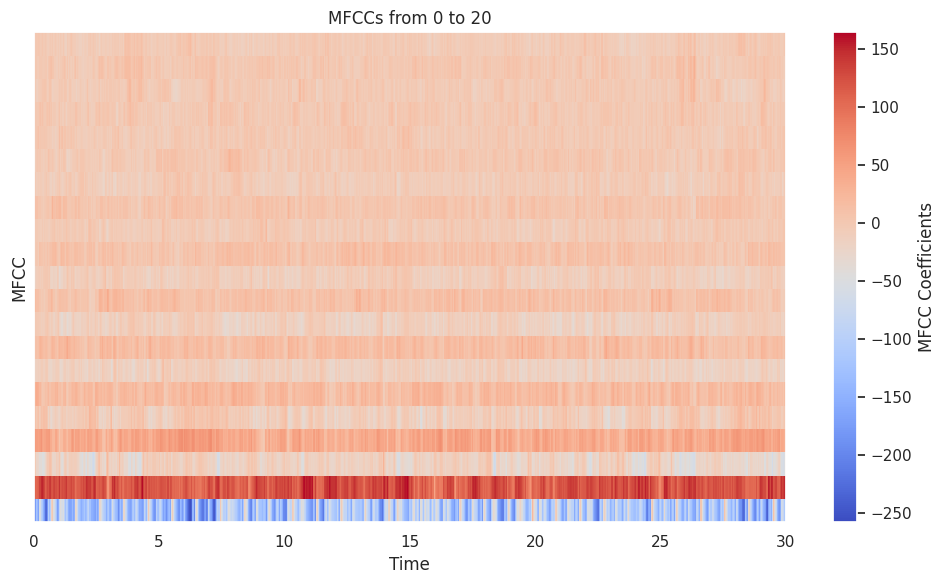

In [144]:
# Let load .wav file with default sampling rate of 22,050Hz
data, sr = librosa.load(data_path)

# Compute the MFCCs
mfccs = librosa.feature.mfcc(y=data, sr=sr, n_mfcc=21)  # Compute 21 MFCCs to include 0 to 20

# Visualize the MFCCs
plt.figure(figsize=(10, 6))
librosa.display.specshow(mfccs, x_axis='time', sr=sr)
plt.colorbar(label='MFCC Coefficients')
plt.ylabel('MFCC')
plt.title('MFCCs from 0 to 20')
plt.tight_layout()
plt.show()

# Tự xây dựng bộ đặc trưng GTZAN từ tín hiệu âm thanh


In [145]:
from glob import glob
import pandas as pd

num_segment=10
num_mfcc=20
sample_rate=22050
n_fft=2048
hop_length=512

my_csv={"filename":[], "chroma_stft_mean": [], "chroma_stft_var": [], "rms_mean": [], "rms_var": [], "spectral_centroid_mean": [],
        "spectral_centroid_var": [], "spectral_bandwidth_mean": [], "spectral_bandwidth_var": [], "rolloff_mean": [], "rolloff_var": [],
        "zero_crossing_rate_mean": [], "zero_crossing_rate_var": [], "harmony_mean": [], "harmony_var": [], "perceptr_mean": [],
        "perceptr_var": [], "tempo": [], "mfcc1_mean": [], "mfcc1_var" : [], "mfcc2_mean" : [], "mfcc2_var" : [],
        "mfcc3_mean" : [], "mfcc3_var" : [], "mfcc4_mean" : [], "mfcc4_var" : [], "mfcc5_mean" : [],
        "mfcc5_var" : [], "mfcc6_mean" : [], "mfcc6_var" : [], "mfcc7_mean" : [], "mfcc7_var" : [],
        "mfcc8_mean" : [], "mfcc8_var" : [], "mfcc9_mean" : [], "mfcc9_var" : [], "mfcc10_mean" : [],
        "mfcc10_var" : [], "mfcc11_mean" : [], "mfcc11_var" : [], "mfcc12_mean" : [], "mfcc12_var" : [],
        "mfcc13_mean" : [], "mfcc13_var" : [], "mfcc14_mean" : [], "mfcc14_var" : [], "mfcc15_mean" : [],
        "mfcc15_var" : [], "mfcc16_mean" : [], "mfcc16_var" : [], "mfcc17_mean" : [], "mfcc17_var" : [],
        "mfcc18_mean" : [], "mfcc18_var" : [], "mfcc19_mean" : [], "mfcc19_var" : [], "mfcc20_mean" : [],
        "mfcc20_var":[], "label":[]}

In [146]:
dataset_path=str(GTZAN_AUDIO)
audio_files = glob(dataset_path + "/*/*")
# genre = glob(dataset_path + "/*")
# n_genres=len(genre)
# genre=[genre[x].split('/')[-1] for x in range(n_genres)]
# print(genre)

In [147]:
samples_per_segment = int(sample_rate*30/num_segment)

genre=""
for f in sorted(audio_files):
    if genre!=f.split('/')[-2]:
        genre=f.split('/')[-2]
        print("Processsing " + genre + "...")
    fname=f.split('/')[-1]
    try:
        y, sr = librosa.load(f, sr=sample_rate)
    except:
        continue

    for n in range(num_segment):
        y_seg = y[samples_per_segment*n: samples_per_segment*(n+1)]
        #Chromagram
        chroma_hop_length = 512
        chromagram = librosa.feature.chroma_stft(y=y_seg, sr=sample_rate, hop_length=chroma_hop_length)
        my_csv["chroma_stft_mean"].append(chromagram.mean())
        my_csv["chroma_stft_var"].append(chromagram.var())

        #Root Mean Square Energy
        RMSEn= librosa.feature.rms(y=y_seg)
        my_csv["rms_mean"].append(RMSEn.mean())
        my_csv["rms_var"].append(RMSEn.var())

        #Spectral Centroid
        spec_cent=librosa.feature.spectral_centroid(y=y_seg)
        my_csv["spectral_centroid_mean"].append(spec_cent.mean())
        my_csv["spectral_centroid_var"].append(spec_cent.var())

        #Spectral Bandwith
        spec_band=librosa.feature.spectral_bandwidth(y=y_seg,sr=sample_rate)
        my_csv["spectral_bandwidth_mean"].append(spec_band.mean())
        my_csv["spectral_bandwidth_var"].append(spec_band.var())

        #Rolloff
        spec_roll=librosa.feature.spectral_rolloff(y=y_seg,sr=sample_rate)
        my_csv["rolloff_mean"].append(spec_roll.mean())
        my_csv["rolloff_var"].append(spec_roll.var())

        #Zero Crossing Rate
        zero_crossing=librosa.feature.zero_crossing_rate(y=y_seg)
        my_csv["zero_crossing_rate_mean"].append(zero_crossing.mean())
        my_csv["zero_crossing_rate_var"].append(zero_crossing.var())

        #Harmonics and Perceptrual
        harmony, perceptr = librosa.effects.hpss(y=y_seg)
        my_csv["harmony_mean"].append(harmony.mean())
        my_csv["harmony_var"].append(harmony.var())
        my_csv["perceptr_mean"].append(perceptr.mean())
        my_csv["perceptr_var"].append(perceptr.var())

        #Tempo
        tempo, _ = librosa.beat.beat_track(y=y_seg, sr=sample_rate)
        my_csv["tempo"].append(tempo)

        #MFCC
        mfcc=librosa.feature.mfcc(y=y_seg,sr=sample_rate, n_mfcc=num_mfcc, n_fft=n_fft, hop_length=hop_length)
        mfcc=mfcc.T


        fseg_name='.'.join(fname.split('.')[:2])+f'.{n}.wav'
        my_csv["filename"].append(fseg_name)
        my_csv["label"].append(genre)
        for x in range(20):
            feat1 = "mfcc" + str(x+1) + "_mean"
            feat2 = "mfcc" + str(x+1) + "_var"
            my_csv[feat1].append(mfcc[:,x].mean())
            my_csv[feat2].append(mfcc[:,x].var())
    print(fname)

df = pd.DataFrame(my_csv)
df.to_csv('/kaggle/working/features_3_sec.csv', index=False)

Processsing blues...
blues.00000.wav
blues.00001.wav
blues.00002.wav
blues.00003.wav
blues.00004.wav
blues.00005.wav
blues.00006.wav
blues.00007.wav
blues.00008.wav
blues.00009.wav
blues.00010.wav
blues.00011.wav
blues.00012.wav
blues.00013.wav
blues.00014.wav
blues.00015.wav
blues.00016.wav
blues.00017.wav
blues.00018.wav
blues.00019.wav
blues.00020.wav
blues.00021.wav
blues.00022.wav
blues.00023.wav
blues.00024.wav
blues.00025.wav
blues.00026.wav
blues.00027.wav
blues.00028.wav
blues.00029.wav
blues.00030.wav
blues.00031.wav
blues.00032.wav
blues.00033.wav
blues.00034.wav
blues.00035.wav
blues.00036.wav
blues.00037.wav
blues.00038.wav
blues.00039.wav
blues.00040.wav
blues.00041.wav
blues.00042.wav
blues.00043.wav
blues.00044.wav
blues.00045.wav
blues.00046.wav
blues.00047.wav
blues.00048.wav
blues.00049.wav
blues.00050.wav
blues.00051.wav
blues.00052.wav
blues.00053.wav
blues.00054.wav
blues.00055.wav
blues.00056.wav
blues.00057.wav
blues.00058.wav
blues.00059.wav
blues.00060.wav
blu

/tmp/ipykernel_49/2192870291.py:10: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(f, sr=sample_rate)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


jazz.00055.wav
jazz.00056.wav
jazz.00057.wav
jazz.00058.wav
jazz.00059.wav
jazz.00060.wav
jazz.00061.wav
jazz.00062.wav
jazz.00063.wav
jazz.00064.wav
jazz.00065.wav
jazz.00066.wav
jazz.00067.wav
jazz.00068.wav
jazz.00069.wav
jazz.00070.wav
jazz.00071.wav
jazz.00072.wav
jazz.00073.wav
jazz.00074.wav
jazz.00075.wav
jazz.00076.wav
jazz.00077.wav
jazz.00078.wav
jazz.00079.wav
jazz.00080.wav
jazz.00081.wav
jazz.00082.wav
jazz.00083.wav
jazz.00084.wav
jazz.00085.wav
jazz.00086.wav
jazz.00087.wav
jazz.00088.wav
jazz.00089.wav
jazz.00090.wav
jazz.00091.wav
jazz.00092.wav
jazz.00093.wav
jazz.00094.wav
jazz.00095.wav
jazz.00096.wav
jazz.00097.wav
jazz.00098.wav
jazz.00099.wav
Processsing metal...
metal.00000.wav
metal.00001.wav
metal.00002.wav
metal.00003.wav
metal.00004.wav
metal.00005.wav
metal.00006.wav
metal.00007.wav
metal.00008.wav
metal.00009.wav
metal.00010.wav
metal.00011.wav
metal.00012.wav
metal.00013.wav
metal.00014.wav
metal.00015.wav
metal.00016.wav
metal.00017.wav
metal.00018.wav


In [148]:
# Reading the csv file
df = pd.read_csv("/kaggle/working/features_3_sec.csv")
df.head()

,filename,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.0.wav,0.335555,0.090997,0.130189,0.003559,1773.358004,169450.829707,1972.334258,117272.640573,3714.063439,...,39.547077,-3.230045,36.606865,0.696384,37.766136,-5.035944,33.668550,-0.239586,43.818886,blues
1,blues.00000.1.wav,0.343523,0.086782,0.112119,0.001491,1817.244034,90766.297514,2010.751494,65940.666037,3870.510442,...,64.819786,-6.025472,40.548820,0.127130,51.048943,-2.808956,97.221504,5.771881,60.360348,blues
2,blues.00000.2.wav,0.347746,0.092495,0.130895,0.004552,1790.722358,110071.206762,2088.184750,73391.498088,4000.206581,...,68.306810,-1.714474,28.136948,2.329551,47.211433,-1.925620,52.922436,2.466995,33.164000,blues
3,blues.00000.3.wav,0.363863,0.087207,0.131349,0.002338,1660.545231,109496.936309,1967.920582,79805.901501,3579.149639,...,48.543198,-3.786986,28.419546,1.153315,35.682700,-3.501979,50.610348,3.580636,32.325880,blues
4,blues.00000.4.wav,0.335481,0.088482,0.142370,0.001734,1634.465076,77425.419156,1954.633566,57359.695597,3480.096905,...,30.829548,0.635799,44.645560,1.591106,51.415867,-3.364908,26.421093,0.501503,29.109533,blues


In [149]:
df.describe()

,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,rolloff_var,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
count,9990.000000,9990.000000,9990.000000,9.990000e+03,9990.000000,9.990000e+03,9990.000000,9.990000e+03,9990.000000,9.990000e+03,...,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000,9990.000000
mean,0.379990,0.084878,0.130072,2.671954e-03,2202.369980,4.159387e+05,2244.896920,1.183063e+05,4572.536972,1.623622e+06,...,1.427954,49.862154,-4.192178,51.817823,0.724029,52.329107,-2.497078,54.794084,-0.928751,57.124855
std,0.090608,0.009674,0.068164,3.560292e-03,750.391602,4.339124e+05,541.333433,1.002217e+05,1639.176635,1.482200e+06,...,5.725414,34.349220,5.667050,36.292803,5.173894,38.055533,5.105615,41.493452,5.245860,46.327534
min,0.108073,0.015217,0.000947,4.055916e-08,479.905803,2.161498e+03,499.577102,1.295350e+03,673.906438,1.130834e+03,...,-26.764162,1.343236,-27.932224,1.531853,-20.749746,3.445752,-27.359077,3.147766,-35.614895,0.253587
25%,0.316091,0.079807,0.083282,6.289852e-04,1634.440203,1.228680e+05,1890.759726,4.943213e+04,3390.961867,5.569716e+05,...,-2.233534,29.516241,-7.944615,29.816507,-2.521760,29.398647,-5.734800,30.382711,-4.012598,29.922275
50%,0.385192,0.085116,0.120503,1.500568e-03,2213.635011,2.646154e+05,2233.838250,9.034532e+04,4636.264273,1.156686e+06,...,1.444074,41.481305,-4.443323,42.215927,0.728383,41.682190,-2.699553,43.243170,-1.044268,44.156442
75%,0.442904,0.091145,0.175398,3.113753e-03,2714.394794,5.611495e+05,2591.195841,1.578898e+05,5597.970252,2.251552e+06,...,5.103708,59.059196,-0.732970,61.422584,3.869063,61.840461,0.521311,65.132600,2.193336,67.996493
max,0.751176,0.120717,0.440458,3.237973e-02,5432.278843,4.801847e+06,3708.279663,1.237131e+06,9486.121357,1.293661e+07,...,39.147713,682.968140,33.869507,523.140600,36.923040,628.774540,31.367567,1147.502600,34.130860,914.816350


In [150]:
# Shape of the data
df.shape

(9990, 59)

In [151]:
# Data type of the data
df.dtypes

filename                    object
chroma_stft_mean           float64
chroma_stft_var            float64
rms_mean                   float64
rms_var                    float64
spectral_centroid_mean     float64
spectral_centroid_var      float64
spectral_bandwidth_mean    float64
spectral_bandwidth_var     float64
rolloff_mean               float64
rolloff_var                float64
zero_crossing_rate_mean    float64
zero_crossing_rate_var     float64
harmony_mean               float64
harmony_var                float64
perceptr_mean              float64
perceptr_var               float64
tempo                       object
mfcc1_mean                 float64
mfcc1_var                  float64
mfcc2_mean                 float64
mfcc2_var                  float64
mfcc3_mean                 float64
mfcc3_var                  float64
mfcc4_mean                 float64
mfcc4_var                  float64
mfcc5_mean                 float64
mfcc5_var                  float64
mfcc6_mean          

In [172]:
# Xóa filename nếu còn tồn tại.
df = df.drop(columns=["filename"], errors="ignore")

In [174]:

# Chỉ xóa cột length nếu có; không có thì bỏ qua.
df = df.drop(columns=["length"], errors="ignore")

In [175]:
X, y =  df.iloc[:,:-1], df.iloc[:,-1]

In [176]:
from sklearn.preprocessing import LabelEncoder

# Label Encoding - encod the categorical classes with numerical integer values for training

# Blues - 0
# Classical - 1
# Country - 2
# Disco - 3
# Hip-hop - 4
# Jazz - 5
# Metal - 6
# Pop - 7
# Reggae - 8
# Rock - 9

encoder=LabelEncoder()
y=encoder.fit_transform(y)
y

array([0, 0, 0, ..., 9, 9, 9])

In [178]:
#scaling
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Tạo lại X từ bảng đặc trưng, giữ nguyên thứ tự các hàng.
X = df.drop(
    columns=["filename", "length", "label"],
    errors="ignore"
).copy()

# Chuyển tempo dạng "[129.19921875]" thành số 129.19921875.
if "tempo" in X.columns:
    X["tempo"] = (
        X["tempo"]
        .astype(str)
        .str.strip()
        .str.strip("[]")
        .str.strip()
    )

# Đảm bảo các đặc trưng đều là số.
# Nếu còn dữ liệu không hợp lệ, báo lỗi thay vì tự thay bằng 0.
X = X.apply(pd.to_numeric, errors="raise")

# Chuẩn hóa như code ban đầu.
scaler = StandardScaler()
X = scaler.fit_transform(X)

print("Chuẩn hóa thành công. Kích thước X:", X.shape)

Chuẩn hóa thành công. Kích thước X: (9990, 57)


In [186]:
from sklearn.model_selection import train_test_split

# splitting 70% data into training set and the remaining 30% to test set
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3, random_state=1234)

In [180]:
# test data size
len(y_test)

2997

In [187]:
# size of training data
len(y_train)

6993

## Thuật toán K láng giềng gần nhất (KNN)

**K-Nearest Neighbors (KNN)** là thuật toán học máy phân loại các điểm dữ liệu dựa trên những điểm lân cận trong không gian đặc trưng. Phương pháp này dựa vào khoảng cách giữa các mẫu. Công thức khoảng cách được minh họa trong tài liệu:

$$d = \sqrt{(x2-x1)^2 - (y2-y1)^2}$$


In [188]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

Training set score: 0.953
Test set score: 0.891
              precision    recall  f1-score   support

           0       0.89      0.93      0.91       312
           1       0.91      0.96      0.93       314
           2       0.81      0.87      0.84       291
           3       0.81      0.92      0.86       300
           4       0.91      0.88      0.90       294
           5       0.90      0.86      0.88       320
           6       0.97      0.93      0.95       295
           7       0.95      0.84      0.89       302
           8       0.86      0.90      0.88       276
           9       0.91      0.82      0.86       293

    accuracy                           0.89      2997
   macro avg       0.89      0.89      0.89      2997
weighted avg       0.89      0.89      0.89      2997



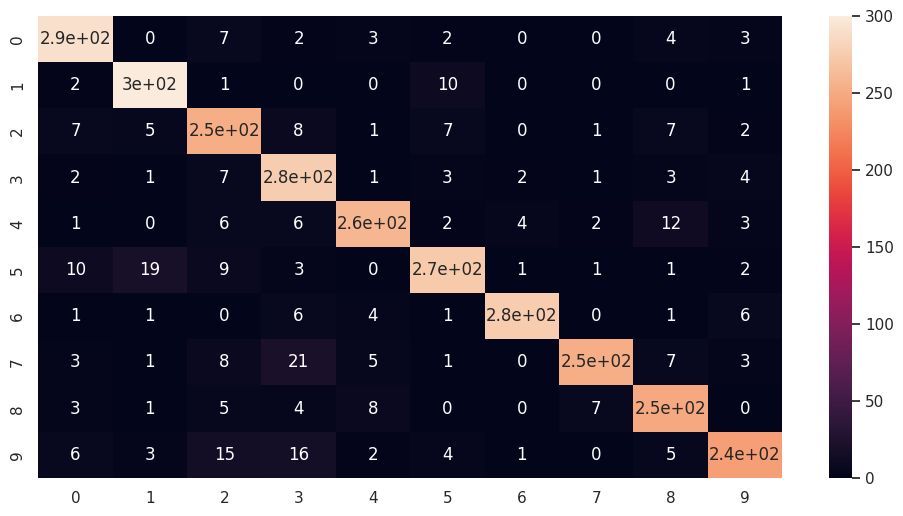

In [189]:
knn_cls=KNeighborsClassifier(n_neighbors=3)
knn_cls.fit(X_train,y_train)
y_pred=knn_cls.predict(X_test)

print("Training set score: {:.3f}".format(knn_cls.score(X_train, y_train)))
print("Test set score: {:.3f}".format(knn_cls.score(X_test, y_test)))

cf_matrix = confusion_matrix(y_test, y_pred)
sns.set(rc = {'figure.figsize':(12,6)})
sns.heatmap(cf_matrix, annot=True)
print(classification_report(y_test,y_pred))

## Máy vector hỗ trợ (Support Vector Machine – SVM)

**SVM** là mô hình học máy thường được sử dụng cho bài toán phân loại. Khi dữ liệu không thể tách tuyến tính, có thể sử dụng các hàm kernel. Ví dụ, hàm kernel sigmoid được viết dưới dạng:

$$K(y_n,y_i) = \tanh(-\gamma*(y_n,y_i)+r)$$


In [192]:
from sklearn.svm import SVC

Training set score: 0.919
Test set score: 0.845
              precision    recall  f1-score   support

           0       0.86      0.85      0.85       312
           1       0.88      0.96      0.92       314
           2       0.81      0.80      0.80       291
           3       0.78      0.80      0.79       300
           4       0.92      0.80      0.86       294
           5       0.87      0.88      0.88       320
           6       0.89      0.91      0.90       295
           7       0.89      0.88      0.89       302
           8       0.80      0.85      0.83       276
           9       0.75      0.71      0.73       293

    accuracy                           0.84      2997
   macro avg       0.84      0.84      0.84      2997
weighted avg       0.85      0.84      0.84      2997



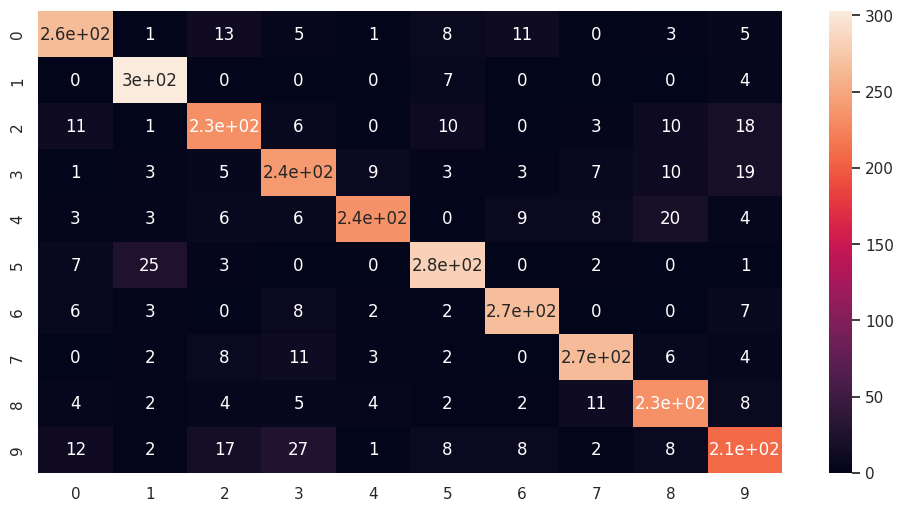

In [193]:
svm_cls = SVC(kernel='rbf', degree=8)
svm_cls.fit(X_train, y_train)

print("Training set score: {:.3f}".format(svm_cls.score(X_train, y_train)))
print("Test set score: {:.3f}".format(svm_cls.score(X_test, y_test)))

y_pred = svm_cls.predict(X_test)

cf_matrix3 = confusion_matrix(y_test, y_pred)
sns.set(rc = {'figure.figsize':(12,6)})
sns.heatmap(cf_matrix3, annot=True)
print(classification_report(y_test, y_pred))

## Mạng nơ-ron truyền thẳng (Feed-forward Neural Network)

### Huấn luyện trên GPU của Kaggle

Bật **GPU** trong phần **Accelerator** của notebook, rồi chạy các ô theo thứ tự. Ô import PyTorch sẽ in thiết bị huấn luyện và tên GPU; nếu không có CUDA, chương trình tự dùng CPU.

Bản chỉnh sửa chỉ chuyển mô hình, dữ liệu và nhãn sang cùng thiết bị; khi xuất dự đoán sang NumPy, kết quả được chuyển về CPU. Sử dụng một GPU (`cuda:0`). Kiến trúc MLP, Softmax, hàm mất mát, optimizer, learning rate, batch size, 300 epoch, chuẩn hóa và cách chia tập đều được giữ nguyên.

Phần trích xuất đặc trưng bằng librosa và các mô hình KNN/SVM hiện tại vẫn chạy trên CPU. Tập kiểm tra vẫn được dùng trong vòng validation như code gốc.


In [194]:
import os
import numpy as np

import torch
from torch import nn, optim
from torch.functional import F
from torch.utils.data import DataLoader, TensorDataset

# Tự chọn một GPU CUDA nếu có, nếu không thì dùng CPU.
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Thiết bị huấn luyện:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))
else:
    print("Chưa nhận GPU. Hãy bật GPU trong phần Accelerator của notebook Kaggle rồi chạy lại.")

Thiết bị huấn luyện: cuda:0
GPU: Tesla T4


In [195]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super(MLP, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(input_size, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 128)
        self.fc4 = nn.Linear(128, 64)
        self.fc5 = nn.Linear(64, 32)
        self.fc6 = nn.Linear(32, 10)
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        x = F.relu(self.fc3(x))
        x = self.dropout(x)
        x = F.relu(self.fc4(x))
        x = self.dropout(x)
        x = F.relu(self.fc5(x))
        x = self.dropout(x)
        x = F.softmax(self.fc6(x), dim=1)
        return x

In [196]:
input_size = X_train.shape[1]
model = MLP(input_size).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.000146)

In [197]:
num_epochs = 300
batch_size = 256

train_dataset = TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(torch.tensor(X_test), torch.tensor(y_test))
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

step = 0

for epoch in range(num_epochs):
    model.train()
    for inputs, labels in train_loader:
        # Chuyển cả dữ liệu và nhãn sang cùng thiết bị với mô hình.
        inputs = inputs.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs.float())
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        if step % 100 ==0:
          print(f"Step {step}, Train Loss: {loss.item():.4f}")
        step += 1

    # Validation
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs.float())
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100 * correct / total
    print(f"Epoch {epoch+1}/{num_epochs}, Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.2f}%")

Step 0, Train Loss: 2.3024
Epoch 1/300, Validation Loss: 2.2999, Validation Accuracy: 17.05%
Epoch 2/300, Validation Loss: 2.2810, Validation Accuracy: 19.19%
Epoch 3/300, Validation Loss: 2.2150, Validation Accuracy: 26.56%
Step 100, Train Loss: 2.1882
Epoch 4/300, Validation Loss: 2.1346, Validation Accuracy: 28.86%
Epoch 5/300, Validation Loss: 2.1136, Validation Accuracy: 32.43%
Epoch 6/300, Validation Loss: 2.0926, Validation Accuracy: 34.60%
Epoch 7/300, Validation Loss: 2.0612, Validation Accuracy: 38.37%
Step 200, Train Loss: 2.0812
Epoch 8/300, Validation Loss: 2.0401, Validation Accuracy: 40.34%
Epoch 9/300, Validation Loss: 2.0213, Validation Accuracy: 42.74%
Epoch 10/300, Validation Loss: 2.0065, Validation Accuracy: 44.51%
Step 300, Train Loss: 1.9892
Epoch 11/300, Validation Loss: 1.9932, Validation Accuracy: 46.45%
Epoch 12/300, Validation Loss: 1.9728, Validation Accuracy: 48.58%
Epoch 13/300, Validation Loss: 1.9606, Validation Accuracy: 50.22%
Epoch 14/300, Validation

Expected Index: [8 7 7 ... 7 0 9], Predicted Index: [8 7 7 ... 2 0 9]
              precision    recall  f1-score   support

           0       0.87      0.84      0.85       312
           1       0.89      0.97      0.93       314
           2       0.78      0.84      0.81       291
           3       0.78      0.81      0.79       300
           4       0.89      0.80      0.84       294
           5       0.87      0.90      0.88       320
           6       0.89      0.90      0.90       295
           7       0.84      0.87      0.85       302
           8       0.82      0.78      0.80       276
           9       0.80      0.70      0.75       293

    accuracy                           0.84      2997
   macro avg       0.84      0.84      0.84      2997
weighted avg       0.84      0.84      0.84      2997



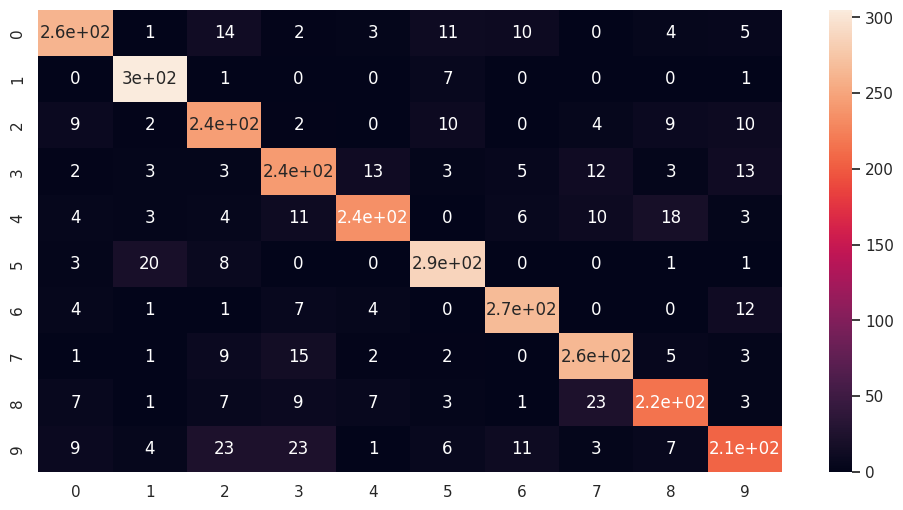

In [198]:
# Sample testing
model.eval()
with torch.no_grad():
    predictions = model(torch.tensor(X_test).float().to(device))
    _, predicted_indices = predictions.max(1)
    print("Expected Index: {}, Predicted Index: {}".format(y_test, predicted_indices.cpu().numpy()))

# Confusion Matrix and Classification Report
from sklearn.metrics import classification_report
import seaborn as sns

y_pred = predicted_indices.cpu().numpy()
cf_matrix = confusion_matrix(y_test, y_pred)
sns.set(rc={'figure.figsize':(12,6)})
sns.heatmap(cf_matrix, annot=True)
print(classification_report(y_test, y_pred))